# TuniShop — 04. EDA Produits : catégories, concentration, gammes, retours

**Auteure :** Sarra Abdeljaouad · **Source :** TuniShop_DWH, lecture directe des vues `bi` (SQL Server) · **Période :** 01/01/2023 – 31/12/2025

**Objectif :** identifier les catégories et les produits qui font le chiffre d'affaires et la marge, et ceux qui reviennent.

| N° (Plan_Analyse_EDA) | Question |
|---|---|
| Q3 | Quelles catégories font le chiffre d'affaires et la marge ? |
| Q4 | Le CA est-il concentré sur quelques produits ? Quelles gammes de prix rapportent ? |
| Q16 | Quelles catégories sont le plus retournées ? |

Pour chaque question : un tableau rappelle l'**hypothèse** du plan d'analyse, les **vues** utilisées et la **méthode** ; puis viennent le calcul (cellules **🔗 SQL direct** exécutées par SQL Server, et pandas), le graphique, la **lecture** et le **verdict** de l'hypothèse (✅ confirmée, 🟡 nuancée, ❌ infirmée).

Les figures sont enregistrées dans `06_Exports/Figures` et les tableaux de résultats dans `06_Exports/Tables` : ils alimentent les rapports de `04_Livrables/EDA`.

## 0. Connexion au DWH et chargement

Le notebook lit les 23 vues `bi.v_*` **en direct** dans SQL Server (réglages dans `00_Commun/tunishop_analytics/config.py`), puis vérifie qu'il s'agit bien du DWH validé.

In [1]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# --- Module commun du projet (dossier 00_Commun, à côté de ce dossier)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, validation, features, temporal_split, publication

warnings.filterwarnings("ignore", category=FutureWarning)      # messages de version sans intérêt ici
cfg.appliquer_style()

# --- Raccourcis
sql = chargement.requete                                       # sql("SELECT ...") -> exécuté par SQL Server

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

In [2]:
chargement.ouvrir_connexion()
vues, p = chargement.charger_donnees(source="dwh")

# Raccourcis vers les tables préparées
cmd, lig, liv, avis, rmb, pai = p["cmd"], p["lig"], p["liv"], p["avis"], p["rmb"], p["pai"]

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)
Lecture directe des vues bi.v_* — 13/11/2026 23:42
  v_dim_date                        1 828 lignes


  v_dim_client                     16 002 lignes
  v_dim_produit                     1 603 lignes
  v_dim_fournisseur                    42 lignes
  v_dim_geographie                     26 lignes
  v_dim_entrepot                        5 lignes
  v_dim_transporteur                    6 lignes
  v_dim_campagne                      154 lignes
  v_dim_coupon                         70 lignes
  v_dim_canal                           8 lignes
  v_dim_mode_paiement                   7 lignes
  v_dim_statut_commande                10 lignes
  v_dim_motif_retour                   14 lignes


  v_fact_ventes                   115 903 lignes


  v_fact_commandes                 66 268 lignes


  v_fact_paiements                 64 491 lignes


  v_fact_livraisons                61 793 lignes


  v_fact_remboursements             8 815 lignes
  v_fact_avis                       9 314 lignes
  v_fact_marketing_quotidien        3 427 lignes


  v_fact_achats_fournisseur        11 793 lignes


  v_fact_mouvements_stock         140 184 lignes


  v_fact_stock_mensuel             56 562 lignes


In [3]:
# Point de départ contrôlé : 5 totaux, valeur validée (PV) = calcul SQL = calcul Python ? (attendu : OK partout)
validation.verifier_coherence(p)

,controle,indicateur,valide_pv,sql_vues_bi,python_pandas,statut
0,C03,Lignes de vente,115 903.000,115 903.000,115 903.000,OK
1,C04,Commandes,66 268.000,66 268.000,66 268.000,OK
2,C05,Livraisons,61 793.000,61 793.000,61 793.000,OK
3,C06,CA reconnu TTC (DT),15 541 665.655,15 541 665.655,15 541 665.655,OK
4,C07,Clients ayant commandé (hors membre inconnu),12 472.000,12 472.000,12 472.000,OK


### Q3. Quelles catégories font le chiffre d'affaires et la marge ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Les catégories qui font le plus de CA ne sont pas celles qui font le plus de marge. |
| **Indicateurs** | CA HT reconnu, marge brute, taux de marge, part du CA par catégorie |
| **Vues bi utilisées** | `v_fact_ventes`, `v_dim_produit`, `v_dim_statut_commande` |
| **Méthode** | pandas |
| **Visualisation** | Deux barres horizontales |
| **Lien data mining / ML** | Prévision par catégorie |

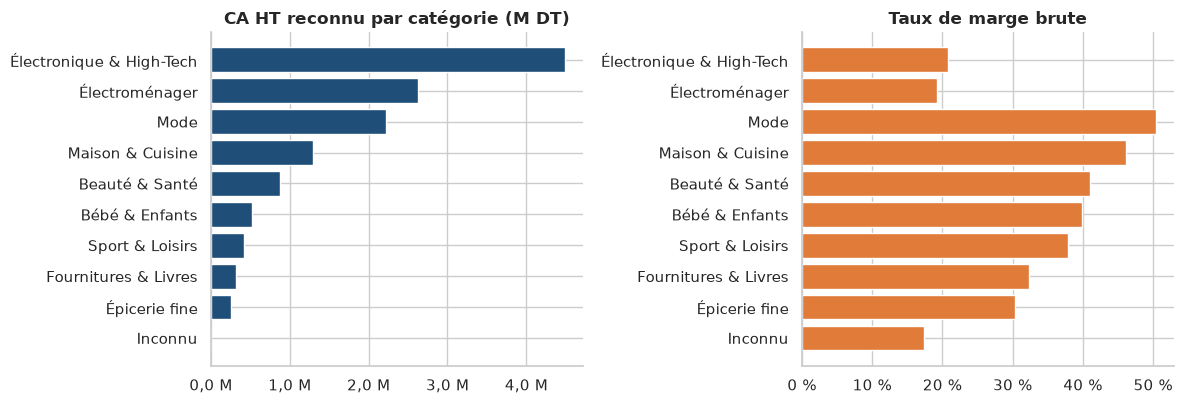

,ca_ht,marge,lignes,taux_marge,part_ca
categorie,,,,,
Électronique & High-Tech,4 493 833.211,932 314.236,14667,0.207,0.345
Électroménager,2 627 675.948,504 976.479,5285,0.192,0.202
Mode,2 215 175.951,1 117 847.602,23100,0.505,0.170
Maison & Cuisine,1 297 568.052,599 469.007,16832,0.462,0.100
Beauté & Santé,872 004.453,357 744.140,12258,0.410,0.067
Bébé & Enfants,517 522.522,206 615.198,6580,0.399,0.040
Sport & Loisirs,419 955.235,158 929.854,2808,0.378,0.032
Fournitures & Livres,320 867.965,103 653.137,13587,0.323,0.025
Épicerie fine,250 238.930,75 878.098,5958,0.303,0.019


In [4]:
la = lig[lig["est_aboutie"]]
cat = la.groupby("categorie").agg(ca_ht=("montant_ht", "sum"), marge=("marge_brute_ht", "sum"), lignes=("ligne_id", "count"))
cat["taux_marge"] = cat["marge"] / cat["ca_ht"]
cat["part_ca"] = cat["ca_ht"] / cat["ca_ht"].sum()
cat = cat.sort_values("ca_ht", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].barh(cat.index[::-1], cat["ca_ht"][::-1], color=cfg.BLEU)
axes[0].set_title("CA HT reconnu par catégorie (M DT)"); cfg.format_millions(axes[0], "x")
axes[1].barh(cat.index[::-1], cat["taux_marge"][::-1], color=cfg.ORANGE)
axes[1].set_title("Taux de marge brute"); cfg.format_pourcent(axes[1], "x")
plt.tight_layout(); montrer("Q03_1")
cat

In [5]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(cat, "Q03_categories")
print("Tableaux exportés.")

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.eda_q03_categories                           10 lignes
Tableaux exportés.


> **Lecture.** L'Électronique & High-Tech fait 34,5 % du CA HT mais avec une marge de 20,7 % ; la **Mode** ne fait que 17 % du CA mais 50,5 % de marge, et rapporte la **plus grosse marge en valeur** (1,12 M DT contre 0,93 M pour l'Électronique). L'Électroménager cumule gros volume et faible marge (19,2 %). **Pour la suite :** la prévision par catégorie doit traiter séparément ces profils très différents.

> ✅ **Verdict : hypothèse confirmée** — l'Électronique fait le plus de CA (34,5 %), la Mode la plus grosse marge en valeur.

### Q4. Le CA est-il concentré sur quelques produits ? Quelles gammes de prix rapportent ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Le CA suit à peu près la règle des 80/20 ; la gamme premium a une marge plus faible. |
| **Indicateurs** | Courbe de Pareto, part des produits pour 80 % du CA, CA et marge par gamme, part des remises promo |
| **Vues bi utilisées** | `v_fact_ventes`, `v_dim_produit`, `v_dim_statut_commande` |
| **Méthode** | SQL direct (gammes) + pandas (Pareto) |
| **Visualisation** | Courbe de Pareto ; tableau par gamme |
| **Lien data mining / ML** | Association : niveau de détail produit ou sous-catégorie |

In [6]:
# 🔗 SQL direct — CA HT, marge et remises promotionnelles par gamme de prix (lignes abouties)
gammes = sql("""
    SELECT pr.gamme_prix,
           COUNT(*)                                            AS lignes,
           SUM(v.montant_ht)                                   AS ca_ht,
           SUM(v.marge_brute_ht) / NULLIF(SUM(v.montant_ht), 0) AS taux_marge,
           SUM(v.montant_remise_promo_ttc) / NULLIF(SUM(v.montant_brut_ttc), 0) AS part_remise_promo
    FROM bi.v_fact_ventes v
    JOIN bi.v_dim_produit pr        ON pr.produit_sk = v.produit_sk
    JOIN bi.v_dim_statut_commande s ON s.statut_commande_sk = v.statut_commande_sk
    WHERE s.famille_statut = 'aboutie'
    GROUP BY pr.gamme_prix
""").set_index("gamme_prix").reindex(["entree", "moyenne", "haute", "premium", "Inconnu"])
gammes["part_ca"] = gammes["ca_ht"] / gammes["ca_ht"].sum()
gammes

,lignes,ca_ht,taux_marge,part_remise_promo,part_ca
gamme_prix,,,,,
entree,49967,1 812 757.556,0.418,0.013,0.139
moyenne,38107,3 759 930.548,0.447,0.027,0.289
haute,10424,2 988 082.612,0.347,0.019,0.229
premium,2577,4 454 071.551,0.131,0.010,0.342
Inconnu,16,5 327.601,0.174,0.000,0.000


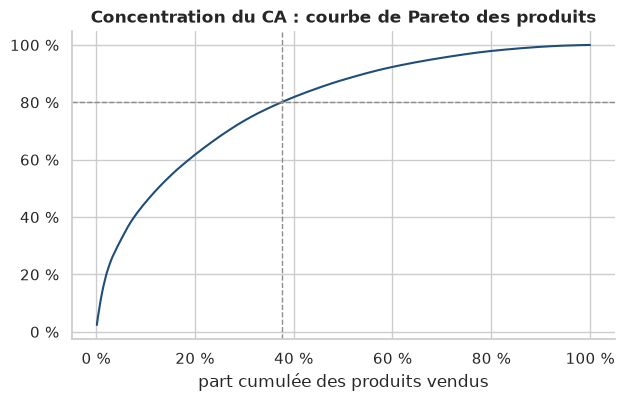

596 produits vendus ; 224 produits (38%) font 80 % du CA HT ; les 20 % premiers font 62% du CA.


In [7]:
# Courbe de Pareto : part cumulée du CA HT selon la part cumulée des produits (du plus vendu au moins vendu)
ca_produit = la.groupby("produit_id")["montant_ht"].sum().sort_values(ascending=False)
part_ca_cumulee = ca_produit.cumsum() / ca_produit.sum()
part_produits = np.arange(1, len(ca_produit) + 1) / len(ca_produit)
nb_80 = int((part_ca_cumulee < 0.8).sum()) + 1                     # produits nécessaires pour 80 % du CA

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(part_produits, part_ca_cumulee.values, color=cfg.BLEU)
ax.axhline(0.8, color=cfg.GRIS, ls="--", lw=1); ax.axvline(nb_80 / len(ca_produit), color=cfg.GRIS, ls="--", lw=1)
ax.set_title("Concentration du CA : courbe de Pareto des produits")
ax.set_xlabel("part cumulée des produits vendus"); cfg.format_pourcent(ax); cfg.format_pourcent(ax, "x")
montrer("Q04_1")
print(f"{len(ca_produit)} produits vendus ; {nb_80} produits ({nb_80 / len(ca_produit):.0%}) font 80 % du CA HT ; "
      f"les 20 % premiers font {ca_produit.head(int(len(ca_produit) * 0.2)).sum() / ca_produit.sum():.0%} du CA.")

In [8]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(gammes, "Q04_gammes_prix")
print("Tableaux exportés.")

  ✔ ana.eda_q04_gammes_prix                           5 lignes
Tableaux exportés.


> **Lecture.** Le CA est **moins concentré** que la règle des 80/20 : il faut 224 produits sur 596 vendus (38 %) pour faire 80 % du CA HT, et les 20 % de produits les plus vendus n'en font que 62 %. Les gammes ont des rôles opposés : la gamme **premium** fait 34 % du CA HT avec seulement **13 % de marge**, la gamme moyenne 29 % du CA avec 45 % de marge. Les remises promotionnelles restent faibles (1 à 2,7 % du montant brut). **Pour le data mining :** avec une longue traîne de produits, les règles d'association se feront plutôt au niveau de la sous-catégorie qu'au niveau du produit (sinon les paires sont trop rares).

> 🟡 **Verdict : hypothèse nuancée** — le CA est moins concentré que 80/20 (38 % des produits pour 80 % du CA) ; la marge faible du premium est confirmée (13 %).

### Q16. Quelles catégories sont le plus retournées ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | La Mode est la catégorie la plus retournée, l'Épicerie fine la moins retournée (contrôles CC14 et CC15). |
| **Indicateurs** | Taux de retour des lignes livrées par catégorie |
| **Vues bi utilisées** | `v_fact_ventes`, `v_fact_remboursements`, `v_dim_produit`, `v_dim_motif_retour` |
| **Méthode** | pandas |
| **Visualisation** | Barres horizontales |
| **Lien data mining / ML** | Contexte (marge nette) ; churn : demandes de remboursement |

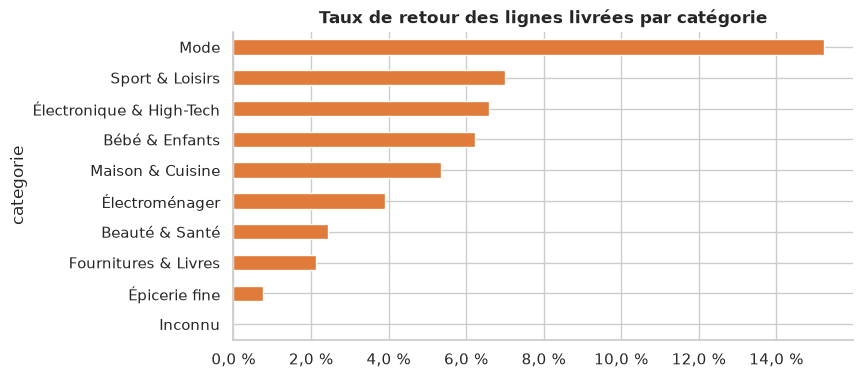

,lignes,taux_retour
categorie,,
Mode,23100,0.152
Sport & Loisirs,2808,0.070
Électronique & High-Tech,14667,0.066
Bébé & Enfants,6580,0.062
Maison & Cuisine,16832,0.054
Électroménager,5285,0.039
Beauté & Santé,12258,0.024
Fournitures & Livres,13587,0.021
Épicerie fine,5958,0.008


In [9]:
retours = la.groupby("categorie")["est_retournee"].agg(lignes="size", taux_retour="mean").sort_values("taux_retour", ascending=False)
ax = retours["taux_retour"].plot.barh(color=cfg.ORANGE, figsize=(8, 4))
ax.invert_yaxis(); ax.set_title("Taux de retour des lignes livrées par catégorie"); cfg.format_pourcent(ax, "x", 1)
montrer("Q16_1")
retours

In [10]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(retours, "Q16_retours_categorie")
print("Tableaux exportés.")

  ✔ ana.eda_q16_retours_categorie                    10 lignes
Tableaux exportés.


> **Lecture.** La **Mode** est de loin la catégorie la plus retournée (15,2 % des lignes livrées, plus du double de la suivante), l'Épicerie fine la moins retournée (0,8 %). Cela explique en partie sa forte marge brute, qui ne tient pas compte des retours.

> ✅ **Verdict : hypothèse confirmée** — Mode 15,2 % de retours, Épicerie fine 0,8 %.

## Synthèse du notebook

| N° | Question | Verdict | Constat clé |
|---|---|---|---|
| Q3 | Quelles catégories font le chiffre d'affaires et la marge ? | ✅ Confirmée | l'Électronique fait le plus de CA (34,5 %), la Mode la plus grosse marge en valeur. |
| Q4 | Le CA est-il concentré sur quelques produits ? Quelles gammes de prix rapportent ? | 🟡 Nuancée | le CA est moins concentré que 80/20 (38 % des produits pour 80 % du CA) ; la marge faible du premium est confirmée (13 %). |
| Q16 | Quelles catégories sont le plus retournées ? | ✅ Confirmée | Mode 15,2 % de retours, Épicerie fine 0,8 %. |

**Ce que ce notebook transmet à la suite :**

- **Association** : longue traîne de produits → règles au niveau de la sous-catégorie ou de la catégorie.
- **Prévision et demande** : profils très différents selon la catégorie (Électronique volume / faible marge, Mode marge / retours) → modèles ou variables par catégorie.

In [11]:
# Verdicts des hypothèses de ce notebook, enregistrés comme les autres résultats :
#   -> 06_Exports/Tables/EDA_hypotheses_04_EDA_Products.csv
#   -> table ana.eda_hypotheses de TuniShop_ANALYTICS (lignes de ce notebook seulement, colonne « notebook »)
verdicts = pd.DataFrame([["Q3", "Ventes et produits", "Quelles catégories font le chiffre d'affaires et la marge ?", "Les catégories qui font le plus de CA ne sont pas celles qui font le plus de marge.", "Confirmée", "l'Électronique fait le plus de CA (34,5 %), la Mode la plus grosse marge en valeur."], ["Q4", "Ventes et produits", "Le CA est-il concentré sur quelques produits ? Quelles gammes de prix rapportent ?", "Le CA suit à peu près la règle des 80/20 ; la gamme premium a une marge plus faible.", "Nuancée", "le CA est moins concentré que 80/20 (38 % des produits pour 80 % du CA) ; la marge faible du premium est confirmée (13 %)."], ["Q16", "Retours, remboursements et avis", "Quelles catégories sont le plus retournées ?", "La Mode est la catégorie la plus retournée, l'Épicerie fine la moins retournée (contrôles CC14 et CC15).", "Confirmée", "Mode 15,2 % de retours, Épicerie fine 0,8 %."]],
                        columns=["question", "theme", "question_metier", "hypothese", "verdict", "constat"])
cfg.exporter_table(verdicts, "EDA_hypotheses_04_EDA_Products", index=False)
verdicts[["question", "verdict"]]

  ✔ ana.eda_hypotheses                                3 lignes


,question,verdict
0,Q3,Confirmée
1,Q4,Nuancée
2,Q16,Confirmée


In [12]:
# Fin du notebook : on ferme les connexions (DWH et base des résultats)
chargement.fermer_connexion()
publication.fermer_connexion()

Connexion fermée.
